# IEEE-CIS Fraud Detection — ДЗ2: контролируемые улучшения, трекинг и абляции

**Курс:** Исследования и разработка в ML  
**Исходное решение:** `baseline_v1` из ДЗ1 ([GitHub](https://github.com/AnastasiaButus/ieee-fraud-detection-ml-rnd))  
**Источник требований:** [HomeWork_2_3.md](https://github.com/PikaChuChuMF/RnD-ML-Course-2026/blob/main/HW_2%2B3/HomeWork_2_3.md)

Исследование посвящено оценке вклада двух групп признаков на неизменном алгоритме логистической регрессии. Внешняя validation из ДЗ1 не используется для подбора улучшений. Численные выводы должны быть сделаны только после исполнения кода.


## 1. Воспроизведение исходной постановки

- Объект: одна онлайн-транзакция; целевая переменная `isFraud`.
- Исходный baseline: `LogisticRegression` на пяти признаках (`TransactionAmt`, `ProductCD`, `card4`, `card6`, `P_emaildomain`).
- Контрольная метрика ДЗ1 на внешней validation: ROC-AUC = **0,749975**, AP = **0,141819**. Это ранее зафиксированный результат, **не результат экспериментов ДЗ2**.
- Протокол сравнения ДЗ2: три expanding-window разбиения внутри исходного train, одинаковые для всех моделей.
- Основная метрика: ROC-AUC. Дополнительные метрики: AP, Precision@1%, Recall@1%.

**Причина выбора протокола:** отсутствует случайное перемешивание будущих транзакций в обучающую часть; показатели новых вариантов сравниваются на одинаковых наблюдениях.


## 2. Гипотезы и зафиксированный план

**H1 (`identity`).** Наличие записи и четыре характеристики устройства/идентификации могут повысить качество выделения рискованных операций. В ДЗ1 увеличение AP для такого набора уже наблюдалось на трёх внутренних фолдах. В ДЗ2 оценивается вклад группы в полной модели и её взаимодействие со второй группой. Наличие признаков на момент реальной авторизации не подтверждено.

**H2 (`C1`, `C2`).** Дополнительные анонимизированные числовые признаки могут описывать аспекты транзакции, отсутствующие в исходных пяти признаках. В предварительном EDA ДЗ1 на train для них не обнаружено пропусков. Их точная семантика не установлена; цель эксперимента — проверить предсказательную полезность, а не приписать причинный смысл.

| ID | `identity` | `C1/C2` | Смысл |
|---|---|---|---|
| A_baseline | нет | нет | Контроль ДЗ1 |
| B_identity | да | нет | Только H1 |
| C_C1_C2 | нет | да | Только H2 |
| D_full | да | да | Обе группы |

**Абляция 1:** `D_full` − `identity` = `C_C1_C2`.  
**Абляция 2:** `D_full` − `C1/C2` = `B_identity`.

Оба удаления выполняются из одной полной конфигурации. Таким образом, проверяется условный вклад каждого компонента, а не произвольное сравнение разных моделей.


## 3. Проверка среды и конфигурации

Эксперимент запускается из корня репозитория, где расположены `src/`, `configs/` и `ieee-fraud-detection.zip`. Исходные данные остаются локальными и не публикуются. Изменения ДЗ2 хранятся в отдельных файлах, исходные конфиги и скрипты ДЗ1 не заменяются.


In [1]:
from pathlib import Path
import json
import platform

import pandas as pd
import sklearn
from IPython.display import display, Image

ROOT = Path.cwd()
CONFIG_PATH = Path("configs/hw2_experiments.json")
required = [
    Path("ieee-fraud-detection.zip"), Path("configs/baseline.json"),
    CONFIG_PATH, Path("src/utils.py"), Path("src/identity_ablation.py"),
    Path("src/hw2_experiments.py"),
]
for file in required:
    print(("OK" if file.is_file() else "НЕ НАЙДЕН"), file)
assert all(f.is_file() for f in required), "Проверка структуры проекта не пройдена."

hw2_config = json.loads(CONFIG_PATH.read_text(encoding="utf-8"))
print("Python:", platform.python_version(), "scikit-learn:", sklearn.__version__)
print("Эксперимент:", hw2_config["experiment_id"])
print("Основная метрика:", hw2_config["primary_metric"])
print("Фолды:", hw2_config["fold_quantiles"])
print("Random state:", hw2_config["random_state"])
display(pd.DataFrame([{"variant": name, **flags} for name, flags in hw2_config["variants"].items()]))

OK ieee-fraud-detection.zip
OK configs\baseline.json
OK configs\hw2_experiments.json
OK src\utils.py
OK src\identity_ablation.py
OK src\hw2_experiments.py
Python: 3.12.4 scikit-learn: 1.4.2
Эксперимент: HW2_ieee_fraud_2x2_feature_groups_v1
Основная метрика: roc_auc
Фолды: [0.4, 0.6, 0.8]
Random state: 42


,variant,add_identity,add_numeric
0,A_baseline,False,False
1,B_identity,True,False
2,C_C1_C2,False,True
3,D_full,True,True


## 4. Проверка новых числовых признаков на исходном train

Перед запуском H2 проверяются наличие, полнота, диапазоны и допустимость логарифмирования `C1`/`C2`. Для оценки характеристик используются **только транзакции исходной train-части**; целевая переменная в этом блоке используется лишь для описательной статистики. Признаки выбраны до просмотра результатов ДЗ2.


In [2]:
from src.utils import load_config, load_transaction_columns, prepare_holdout

base_cfg = load_config("configs/baseline.json")
selected = ["TransactionID", "TransactionDT", "isFraud", "C1", "C2"]
small = load_transaction_columns(base_cfg["archive"], selected)
original_train, original_val, outer_cutoff = prepare_holdout(small, base_cfg)

assert len(original_train) == 472_432 and len(original_val) == 118_108
assert original_train["TransactionDT"].max() < original_val["TransactionDT"].min()

new_features_stats = pd.DataFrame({
    "тип": original_train[["C1", "C2"]].dtypes.astype(str),
    "пропусков": original_train[["C1", "C2"]].isna().sum(),
    "min": original_train[["C1", "C2"]].min(),
    "median": original_train[["C1", "C2"]].median(),
    "p99": original_train[["C1", "C2"]].quantile(.99),
    "max": original_train[["C1", "C2"]].max(),
})
display(new_features_stats)
assert (original_train[["C1", "C2"]].min() >= 0).all(), "Найдены отрицательные значения: log1p требует проверки."
print("Проверка числовых признаков выполнена на train. Внешняя validation при исследовании признаков не анализировалась.")

,тип,пропусков,min,median,p99,max
C1,float64,0,0.0,1.0,168.0,4685.0
C2,float64,0,0.0,1.0,157.0,5691.0


Проверка числовых признаков выполнена на train. Внешняя validation при исследовании признаков не анализировалась.


## 5. Фиксированный протокол честного сравнения

1. Все четыре варианта используют **одни и те же** временные границы квантилей `[0.4, 0.6, 0.8]` исходной train-части и одинаковый набор объектов на каждом фолде.
2. В каждом фолде обучение выполняется только на более ранних транзакциях, без доступа к целевым значениям более позднего периода.
3. Логистическая регрессия, гиперпараметры и `random_state=42` неизменны. Временное разделение детерминировано, поэтому seed не определяет состав train/validation.
4. **Общая схема предобработки не меняется:** `median → log1p → StandardScaler` для числовых признаков, `constant → OneHotEncoder` для категорий. При добавлении новых полей та же схема применяется к новым столбцам, обучается только на train соответствующего фолда.
5. Основная метрика и вспомогательные показатели рассчитываются одинаковым способом для всех вариантов.
6. `TransactionID`, `TransactionDT`, `isFraud` исключены из входных признаков классификатора. `identity` присоединяется без размножения строк.
7. Основной holdout ДЗ1 не используется для выбора лучшей версии. При сравнении временных фолдов среднее ± std трактуется описательно, а не как доверительный интервал.


## 6. Запуск 12 фиксированных экспериментов

Скрипт `src/hw2_experiments.py` выполняет четыре варианта на трёх фолдах, создаёт единый реестр запусков с конфигурациями, метриками и seed, а также две абляционные таблицы. Число запусков фиксировано протоколом; поиск гиперпараметров не производится.


In [3]:
import subprocess
import sys

RUN_HW2_EXPERIMENTS = True

if RUN_HW2_EXPERIMENTS:
    subprocess.run(
        [sys.executable, "-m", "src.hw2_experiments", "--config", str(CONFIG_PATH)],
        cwd=ROOT, check=True,
    )
else:
    print("Запуск отключён. Для выполнения требуется RUN_HW2_EXPERIMENTS = True.")

## 7. Таблица экспериментов и абляционные эффекты

Результаты загружаются из сохранённых CSV, а не вводятся вручную. В таблице абсолютные разницы вычисляются относительно исходного `A_baseline`. Для абляций применяется разница `D_full − вариант без компонента` на одинаковом фолде.

Положительный эффект удаления компонента не гарантируется. При отрицательном или неоднородном эффекте это фиксируется как результат эксперимента.


In [4]:
RESULTS_DIR = Path(hw2_config["results_dir"])
runs = pd.read_csv(RESULTS_DIR / "experiments_by_fold.csv")
summary = pd.read_csv(RESULTS_DIR / "experiments_summary.csv")
ablations = pd.read_csv(RESULTS_DIR / "ablation_by_fold.csv")
ablations_summary = pd.read_csv(RESULTS_DIR / "ablation_summary.csv")

assert runs.shape[0] == 12
assert runs.groupby("fold")["validation_rows"].nunique().eq(1).all()
assert runs.groupby("fold")["validation_fraud_rate"].nunique().eq(1).all()
assert runs["seed"].nunique() == 1 and int(runs["seed"].iloc[0]) == 42

print("Реестр запусков:")
display(runs[["run_id", "hypothesis", "fold", "variant", "seed", "roc_auc", "average_precision", "precision_at_1pct"]].round(5))
print("Средние метрики:")
display(summary.round(5))
print("Две абляции, разницы по фолдам:")
display(ablations[["fold", "ablation", "delta_full_minus_without_roc_auc", "delta_full_minus_without_average_precision"]].round(5))
print("Абляции, сводка:")
display(ablations_summary.round(5))

Реестр запусков:


,run_id,hypothesis,fold,variant,seed,roc_auc,average_precision,precision_at_1pct
0,hw2_f1_A_baseline,Контроль: исходный baseline,1,A_baseline,42,0.73466,0.13693,0.28254
1,hw2_f1_B_identity,H_identity: вклад полей identity,1,B_identity,42,0.73128,0.18056,0.39048
2,hw2_f1_C_C1_C2,H_numeric: вклад C1 и C2,1,C_C1_C2,42,0.73918,0.20025,0.48254
3,hw2_f1_D_full,H_joint: совместное использование обеих групп,1,D_full,42,0.73385,0.23969,0.56402
4,hw2_f2_A_baseline,Контроль: исходный baseline,2,A_baseline,42,0.74017,0.11045,0.17778
5,hw2_f2_B_identity,H_identity: вклад полей identity,2,B_identity,42,0.74984,0.13536,0.30370
6,hw2_f2_C_C1_C2,H_numeric: вклад C1 и C2,2,C_C1_C2,42,0.73865,0.14534,0.31534
7,hw2_f2_D_full,H_joint: совместное использование обеих групп,2,D_full,42,0.74591,0.17156,0.39471
8,hw2_f3_A_baseline,Контроль: исходный baseline,3,A_baseline,42,0.77377,0.17625,0.34921
9,hw2_f3_B_identity,H_identity: вклад полей identity,3,B_identity,42,0.77643,0.20699,0.43386


Средние метрики:


,variant,roc_auc_mean,average_precision_mean,precision_at_1pct_mean,recall_at_1pct_mean,roc_auc_std,average_precision_std,precision_at_1pct_std,recall_at_1pct_std,n_folds,delta_roc_auc_vs_A,delta_average_precision_vs_A,delta_precision_at_1pct_vs_A,delta_recall_at_1pct_vs_A
0,A_baseline,0.74953,0.14121,0.26984,0.06831,0.02117,0.03311,0.08642,0.01981,3,0.00000,0.00000,0.00000,0.00000
1,B_identity,0.75252,0.17430,0.37601,0.09566,0.02269,0.03622,0.06627,0.01344,3,0.00299,0.03309,0.10617,0.02735
2,C_C1_C2,0.74988,0.21143,0.47619,0.12068,0.01899,0.07233,0.15777,0.03702,3,0.00035,0.07022,0.20635,0.05236
3,D_full,0.75126,0.23791,0.53827,0.13659,0.02061,0.06548,0.13258,0.02885,3,0.00173,0.09670,0.26843,0.06828


Две абляции, разницы по фолдам:


,fold,ablation,delta_full_minus_without_roc_auc,delta_full_minus_without_average_precision
0,1,without_identity,-0.00533,0.03944
1,2,without_identity,0.00725,0.02622
2,3,without_identity,0.00222,0.01377
3,1,without_C1_C2,0.00257,0.05913
4,2,without_C1_C2,-0.00393,0.03620
5,3,without_C1_C2,-0.00241,0.09549


Абляции, сводка:


,ablation,delta_full_minus_without_roc_auc_mean,delta_full_minus_without_roc_auc_std,delta_full_minus_without_average_precision_mean,delta_full_minus_without_average_precision_std,delta_full_minus_without_precision_at_1pct_mean,delta_full_minus_without_precision_at_1pct_std,delta_full_minus_without_recall_at_1pct_mean,delta_full_minus_without_recall_at_1pct_std
0,without_identity,0.00138,0.00633,0.02648,0.01283,0.06208,0.03179,0.01591,0.00831
1,without_C1_C2,-0.00126,0.00340,0.06361,0.02990,0.16226,0.06633,0.04093,0.01565


## 8. Графики и журнал экспериментов

Графики представляют метрики по отдельным временным фолдам и условный вклад каждой группы признаков. При сравнении AP учитывается различие базовой частоты мошенничества между фолдами.


roc_auc_by_fold.png


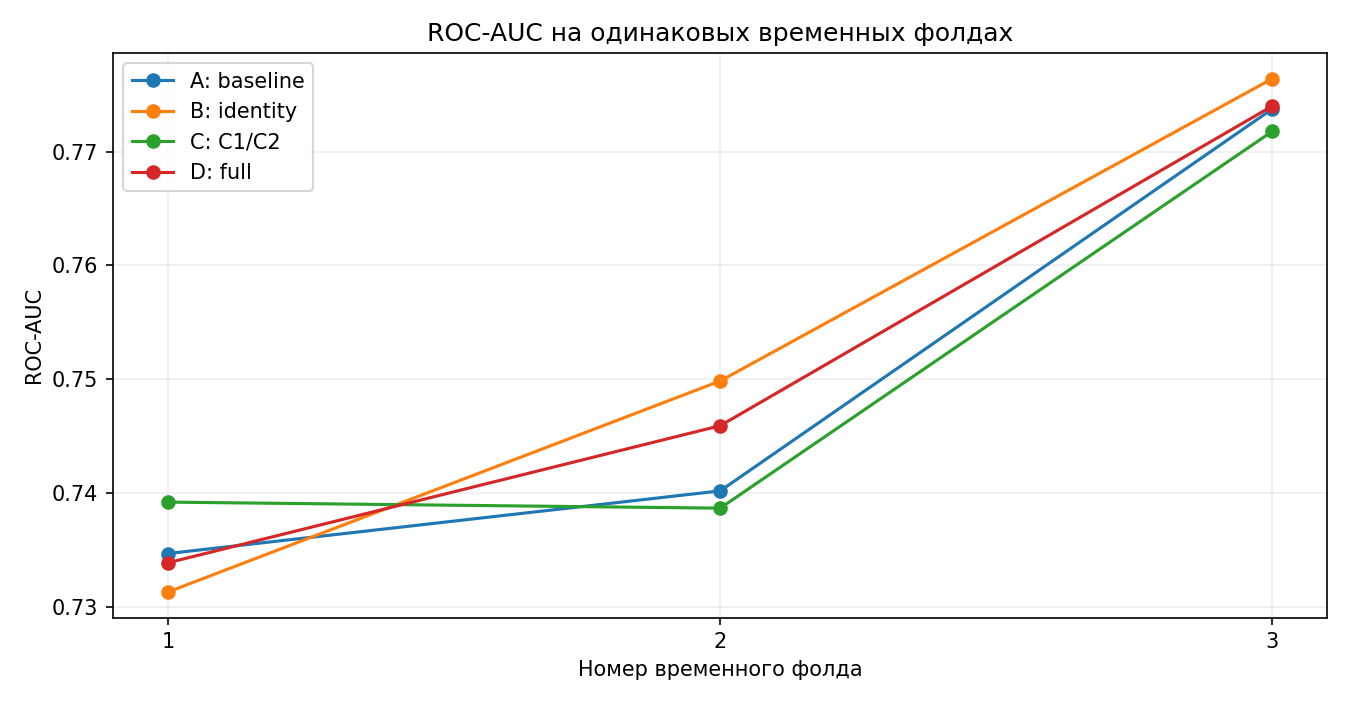

ap_by_fold.png


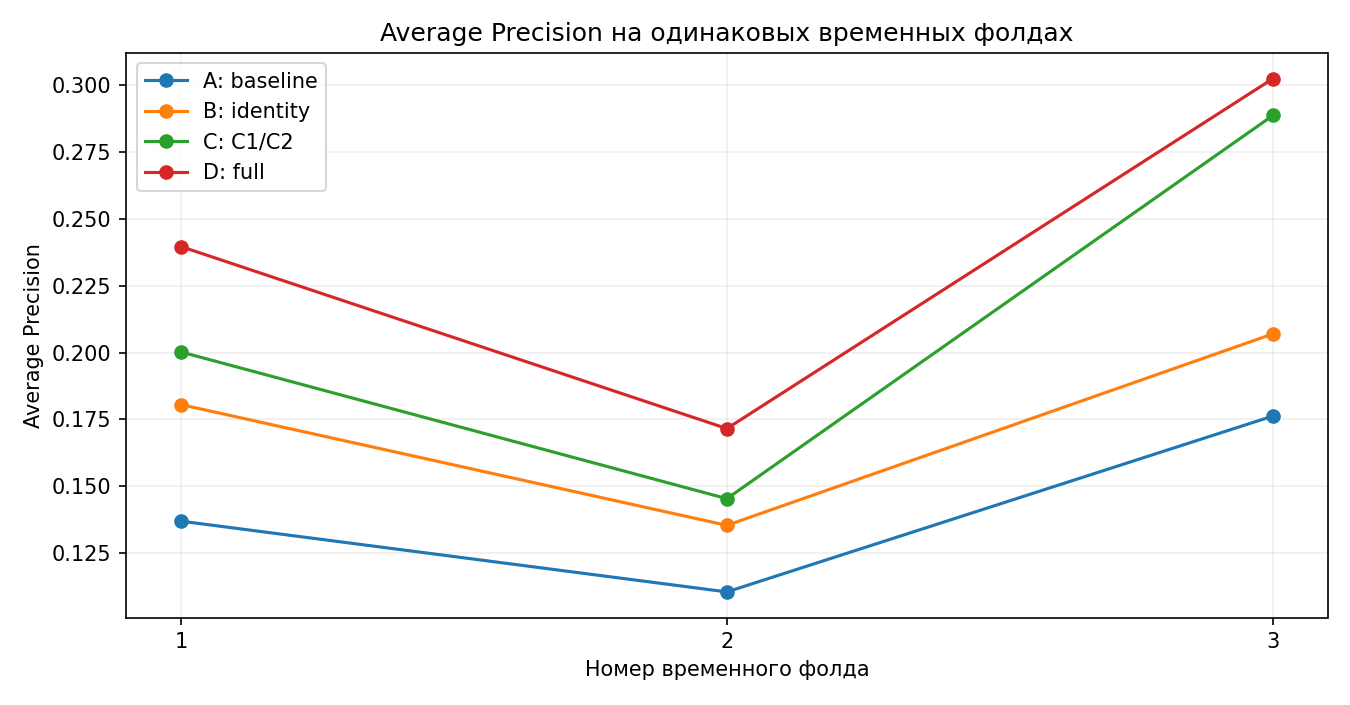

ablation_delta_roc_auc.png


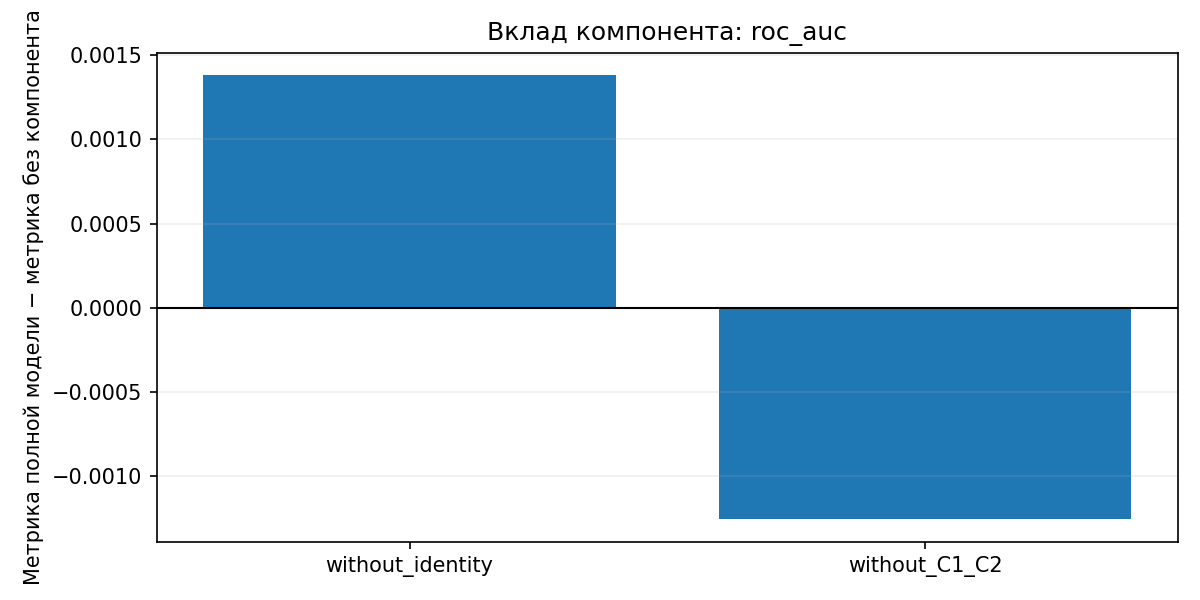

ablation_delta_ap.png


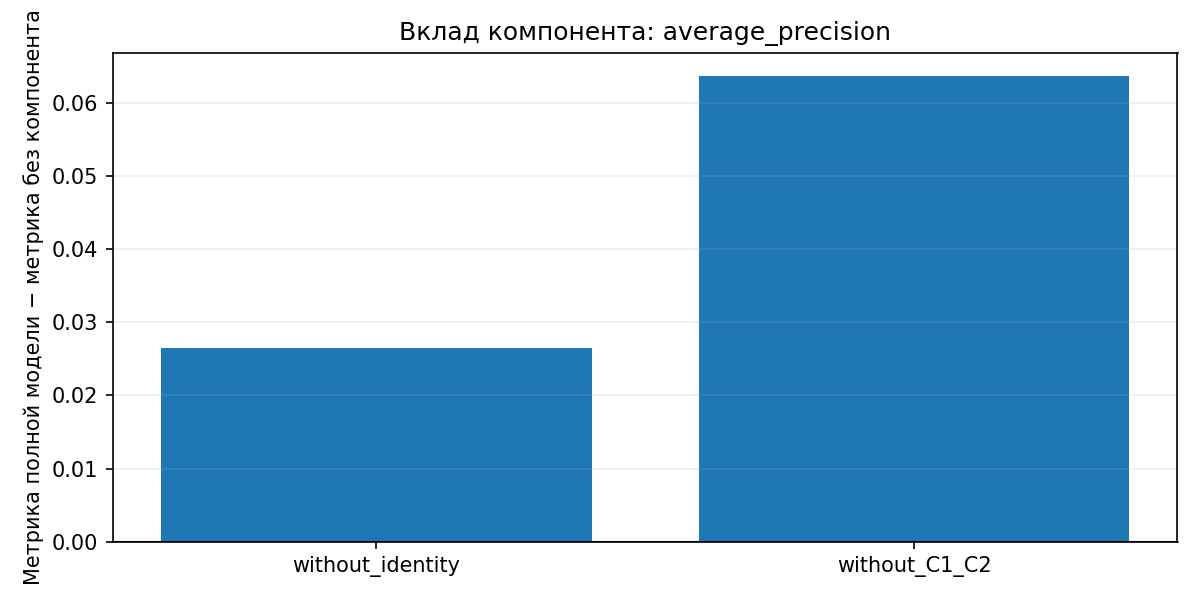

Контроль исходного baseline: {'comparison_available': True, 'max_abs_difference': {'roc_auc': 0.0, 'average_precision': 8.326672684688674e-17}}
Версии среды: {'python': '3.12.4', 'pandas': '2.2.2', 'numpy': '1.26.4', 'sklearn': '1.4.2'}
Число зарегистрированных запусков: 12


In [5]:
for name in [
    "roc_auc_by_fold.png", "ap_by_fold.png",
    "ablation_delta_roc_auc.png", "ablation_delta_ap.png",
]:
    print(name)
    display(Image(filename=str(RESULTS_DIR / name)))

manifest = json.loads((RESULTS_DIR / "run_manifest.json").read_text(encoding="utf-8"))
print("Контроль исходного baseline:", manifest["original_baseline_control"])
print("Версии среды:", manifest["environment"])
print("Число зарегистрированных запусков:", len(runs))

## 9. Научная интерпретация полученных результатов

### Предварительная проверка новых признаков

На исходной обучающей части (без просмотра внешней validation) обнаружено, что `C1` и `C2` имеют числовой тип и не содержат пропусков. Для `C1`: минимум 0, медиана 1, 99-й процентиль 168, максимум 4685. Для `C2`: минимум 0, медиана 1, 99-й процентиль 157, максимум 5691. Значительный разброс обосновывает использование исходного преобразования `log1p`, но не доказывает, что оно само обеспечивает прирост качества. Семантика этих анонимизированных признаков остаётся неизвестной.

### Реестр моделей и результаты на трёх внутренних фолдах

Все четыре варианта обучались на одинаковых трёх временных разбиениях внутри train из ДЗ1. В реестре `results/hw2/experiment_registry.csv` каждому запуску соответствует уникальный `run_id`, гипотеза, состав признаков, seed 42, параметры, метрики и длительность. Полный протокол и контрольные суммы конфигов хранятся в `results/hw2/run_manifest.json`.

| Вариант | ROC-AUC (mean ± std) | AP (mean ± std) | Precision@1% (mean) | Recall@1% (mean) |
|---|---:|---:|---:|---:|
| A — исходный baseline | 0,74953 ± 0,02117 | 0,14121 ± 0,03311 | 0,26984 | 0,06831 |
| B — + `identity` | **0,75252 ± 0,02269** | 0,17430 ± 0,03622 | 0,37601 | 0,09566 |
| C — + `C1`/`C2` | 0,74988 ± 0,01899 | 0,21143 ± 0,07233 | 0,47619 | 0,12068 |
| D — обе группы | 0,75126 ± 0,02061 | **0,23791 ± 0,06548** | **0,53827** | **0,13659** |

По **заранее определённой основной метрике ROC-AUC лучший средний результат у варианта B**, а не у D. Преимущество B над A невелико (+0,00299); статистическая значимость не оценивалась. По AP и метрикам отбора top-1% лучше вариант D: относительно A средний прирост AP +0,09670, Precision@1% +0,26843 (26,84 процентного пункта), Recall@1% +0,06828 (6,83 процентного пункта). Менять основную метрику задним числом нельзя: для варианта D фиксируется преимущество по дополнительным, операционно значимым метрикам, но не лидерство по ROC-AUC.

| Фолд | ROC-AUC A | ROC-AUC B | ROC-AUC C | ROC-AUC D | AP A | AP B | AP C | AP D |
|---:|---:|---:|---:|---:|---:|---:|---:|---:|
| 1 | 0,73466 | 0,73128 | 0,73918 | 0,73385 | 0,13693 | 0,18056 | 0,20025 | 0,23969 |
| 2 | 0,74017 | 0,74984 | 0,73865 | 0,74591 | 0,11045 | 0,13536 | 0,14534 | 0,17156 |
| 3 | 0,77377 | 0,77643 | 0,77118 | 0,77402 | 0,17625 | 0,20699 | 0,28871 | 0,30248 |

### Две абляции относительно полной модели D

Абляционная разница определяется как `metric(D_full) − metric(без группы)`: положительное значение показывает пользу группы *при наличии второй группы*. Каждое сравнение проводится в рамках одного и того же фолда, что исключает влияние различий в распространённости мошенничества между сравниваемыми вариантами.

| Абляция | Сравнение | Δ ROC-AUC (mean) | Δ AP (mean) | Δ Precision@1% (mean) | Δ Recall@1% (mean) |
|---|---|---:|---:|---:|---:|
| Удаление `identity` | D − C | +0,00138 | +0,02648 | +0,06208 | +0,01591 |
| Удаление `C1`/`C2` | D − B | −0,00126 | +0,06361 | +0,16226 | +0,04093 |

**Вывод по абляции `identity`.** AP полной модели выше, чем у D без `identity`, во всех трёх фолдах: +0,03944, +0,02622 и +0,01377. Прирост ROC-AUC неоднороден: −0,00533, +0,00725, +0,00222. Следовательно, группа полезна для AP в исследованных периодах, но её устойчивое положительное влияние на ROC-AUC не подтверждено.

**Вывод по абляции `C1`/`C2`.** AP полной модели выше, чем у D без новых числовых признаков, во всех трёх фолдах: +0,05913, +0,03620 и +0,09549. При этом изменения ROC-AUC составляют +0,00257, −0,00393, −0,00241; средняя разница отрицательна. Значит, улучшение выделения наиболее рискованных транзакций не сопровождается устойчивым улучшением глобального ранжирования.

### Краткая интерпретация и ограничения

1. **H_identity:** при неизменных условиях группа `identity` связана с положительными изменениями AP и метрик top-1% по сравнению с контролем; вклад в ROC-AUC различается по периодам. В отличие от нового признакового эксперимента, ценность `identity` уже предварительно исследовалась в ДЗ1; в ДЗ2 она оценивается также в присутствии `C1`/`C2`.
2. **H_numeric:** `C1` и `C2` дают наиболее заметный дополнительный вклад в AP и Precision@1%, однако почти не повышают средний ROC-AUC и могут его снижать в модели D.
3. **Совместное включение:** вариант D превосходит A по всем перечисленным средним метрикам, но не является лучшим по заранее установленной основной метрике. Предположение об универсальном улучшении качества следует отклонить.
4. **Граница доказательности:** анализ включает только три зависимых временных фолда. Разброс метрик и знакопеременные эффекты могут быть связаны с изменением состава транзакций, распространённости мошенничества и нестабильностью сигналов; без дополнительных данных нельзя установить точную причину. Статистический тест и доверительные интервалы не выполнялись.
5. **Риск утечки:** происхождение и доступность анонимизированных `C1`, `C2` и полей `identity` на момент авторизации не подтверждены; хронологическое разделение и `Pipeline` защищают от утечки через подготовку данных, но не разрешают этот вопрос.

**Решение для следующих шагов.** При отборе по заранее зафиксированной основной метрике кандидат B имеет наибольший средний ROC-AUC, хотя преимущество очень мало. D остаётся отдельным перспективным кандидатом для прикладного сценария с квотой проверок и требовал бы самостоятельной проверки на новом периоде. Внешний holdout ДЗ1 не использовался для сравнения A/B/C/D и настройки модели.

**Обязательные артефакты:** `experiment_registry.csv`, `experiments_by_fold.csv`, `experiments_summary.csv`, `ablation_by_fold.csv`, `ablation_summary.csv`, `run_manifest.json`, графики `roc_auc_by_fold.png`, `ap_by_fold.png`, `ablation_delta_roc_auc.png`, `ablation_delta_ap.png` в `results/hw2/`.



## 10. Контроль полноты и воспроизводимости исследования

Перед публикацией выполняется проверка сохранённых артефактов, полноты реестра запусков, согласованности временных разбиений и результатов контрольного baseline.

Проверка охватывает четыре варианта модели на трёх одинаковых временных фолдах и два абляционных сравнения. Исходные транзакции и построчные предсказания не публикуются.


In [6]:

import numpy as np

# Проверка обязательных артефактов.
required_artifacts = [
    "experiment_registry.csv",
    "experiments_by_fold.csv",
    "experiments_summary.csv",
    "ablation_by_fold.csv",
    "ablation_summary.csv",
    "run_manifest.json",
    "roc_auc_by_fold.png",
    "ap_by_fold.png",
    "ablation_delta_roc_auc.png",
    "ablation_delta_ap.png",
]

artifact_status = pd.DataFrame([
    {
        "файл": name,
        "найден": (RESULTS_DIR / name).is_file(),
    }
    for name in required_artifacts
])

display(artifact_status)
assert artifact_status["найден"].all(), (
    "Отсутствуют обязательные артефакты ДЗ2."
)

# Проверка структуры экспериментального реестра.
expected_variants = {
    "A_baseline",
    "B_identity",
    "C_C1_C2",
    "D_full",
}

assert len(runs) == 12
assert runs["run_id"].is_unique
assert set(runs["variant"]) == expected_variants
assert set(runs["fold"]) == {1, 2, 3}
assert set(runs["seed"]) == {42}

# На каждом фолде представлены все четыре варианта.
for fold, group in runs.groupby("fold"):
    assert set(group["variant"]) == expected_variants
    assert group["train_rows"].nunique() == 1
    assert group["validation_rows"].nunique() == 1
    assert group["validation_fraud_rate"].nunique() == 1
    assert (group["train_max_dt"] < group["validation_min_dt"]).all()

# Проверка корректности рассчитанных метрик.
metrics = [
    "roc_auc",
    "average_precision",
    "precision_at_1pct",
    "recall_at_1pct",
]

assert np.isfinite(runs[metrics].to_numpy()).all()
assert runs[metrics].ge(0).all().all()
assert runs[metrics].le(1).all().all()

# Контроль воспроизведения исходного baseline.
control = manifest["original_baseline_control"]

assert control["comparison_available"]
assert control["max_abs_difference"]["roc_auc"] < 1e-5
assert control["max_abs_difference"]["average_precision"] < 1e-5

# Проверка наличия обеих абляций на каждом фолде.
expected_ablations = {"without_identity", "without_C1_C2"}

assert set(ablations["ablation"]) == expected_ablations

for name, group in ablations.groupby("ablation"):
    assert set(group["fold"]) == {1, 2, 3}

print("Проверка пройдена.")
print("Зарегистрировано запусков:", len(runs))
print("Число вариантов:", runs["variant"].nunique())
print("Число абляционных сравнений:", len(ablations))
print("Обязательных артефактов:", len(required_artifacts))

,файл,найден
0,experiment_registry.csv,True
1,experiments_by_fold.csv,True
2,experiments_summary.csv,True
3,ablation_by_fold.csv,True
4,ablation_summary.csv,True
5,run_manifest.json,True
6,roc_auc_by_fold.png,True
7,ap_by_fold.png,True
8,ablation_delta_roc_auc.png,True
9,ablation_delta_ap.png,True


Проверка пройдена.
Зарегистрировано запусков: 12
Число вариантов: 4
Число абляционных сравнений: 6
Обязательных артефактов: 10
